In [ ]:
import os
# https://stackoverflow.com/questions/20554074/sklearn-omp-error-15-initializing-libiomp5md-dll-but-found-mk2iomp5md-dll-a
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

import mitsuba as mi
import drjit as dr

import numpy as np
import torch

import matplotlib.pyplot as plt
import drjit.nn as nn

from tqdm.auto import tqdm
import imageio.v3 as iio

from drjit.opt import Adam, GradScaler
from drjit.auto.ad import Texture2f, TensorXf, TensorXf16, TensorXf, Float16, Float32, Array1f, Array2f, Array3f

import normflows as nf

import matplotlib.pyplot as plt

jitc_llvm_init(): LLVM API initialization failed ..


In [ ]:
print(mi.variants())

# mi.set_variant("llvm_ad_rgb")
mi.set_variant("cuda_ad_rgb")

['scalar_rgb', 'scalar_spectral', 'scalar_spectral_polarized', 'llvm_ad_rgb', 'llvm_ad_mono', 'llvm_ad_mono_polarized', 'llvm_ad_spectral', 'llvm_ad_spectral_polarized', 'cuda_ad_rgb', 'cuda_ad_mono', 'cuda_ad_mono_polarized', 'cuda_ad_spectral', 'cuda_ad_spectral_polarized']


Sequential(
  TriEncode(octaves=16, shift=0.2, in_channels=2, out_features=64),
  Cast(dtype=Float16),
  Linear(in_features=64, out_features=64, bias=False),
  LeakyReLU(),
  Linear(in_features=64, out_features=64, bias=False),
  LeakyReLU(),
  Linear(in_features=64, out_features=64, bias=False),
  LeakyReLU(),
  Linear(in_features=64, out_features=3, bias=False),
  Exp()
)


  0%|          | 0/1 [00:00<?, ?it/s]

grad var: [0, 0, 0, .. 24570 skipped .., 0, 0, 0]

num not 0: 0


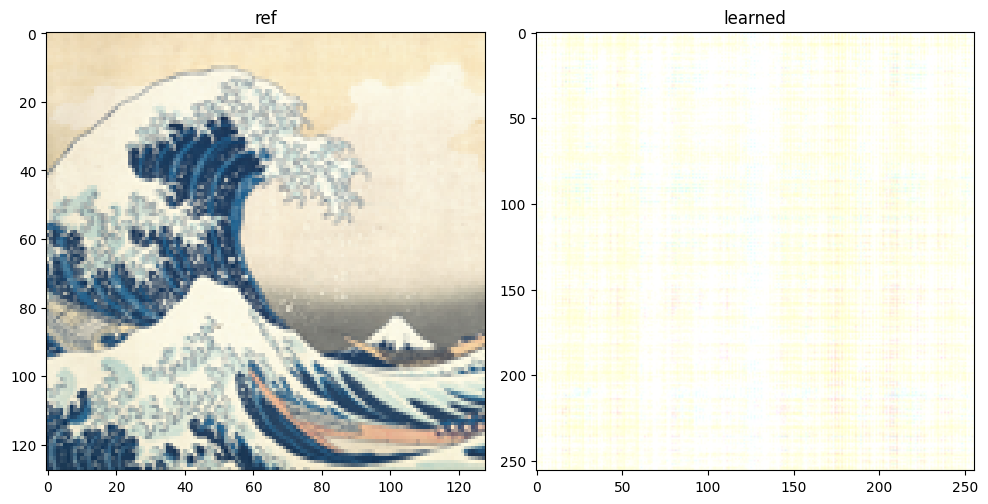

In [ ]:
# Load a test image and construct a texture object
ref = TensorXf(iio.imread("https://d38rqfq1h7iukm.cloudfront.net/media/uploads/wjakob/2024/06/wave-128.png") / 256)
tex = Texture2f(ref)

# Establish the network structure
net = nn.Sequential(
    nn.TriEncode(16, 0.2),
    nn.Cast(Float16),
    nn.Linear(-1, -1, bias=False),
    nn.LeakyReLU(),
    nn.Linear(-1, -1, bias=False),
    nn.LeakyReLU(),
    nn.Linear(-1, -1, bias=False),
    nn.LeakyReLU(),
    nn.Linear(-1, 3, bias=False),
    nn.Exp()
)

# Instantiate a random number generator to initialize the network weights
rng = dr.rng(seed=0)

# Instantiate the network for a specific backend + input size
net = net.alloc(
    dtype=TensorXf16,
    size=2,
    rng=rng
)

# Convert to training-optimal layout
weights, net = nn.pack(net, layout='training')
print(net)

# Optimize a single-precision copy of the parameters
opt = Adam(lr=1e-3, params={'weights': Float32(weights)})

# This is an adaptive mixed-precision (AMP) optimization, where a half
# precision computation runs within a larger single-precision program.
# Gradient scaling is required to make this numerically well-behaved.
scaler = GradScaler()

res = 256

for i in tqdm(range(1)):
    # Update network state from optimizer
    weights[:] = Float16(opt['weights'])

    # Generate jittered positions on [0, 1]^2
    t = dr.arange(Float32, res)
    p = (Array2f(dr.meshgrid(t, t)) + rng.random(Array2f, (2, res * res))) / res

    # Evaluate neural net + L2 loss
    img = Array3f(net(nn.CoopVec(p)))
    loss = dr.squared_norm(tex.eval(p) - img)

    # Mixed-precision training: take suitably scaled steps
    dr.backward(scaler.scale(loss))

    # grad_var = dr.grad(Float16(opt['weights']))
    grad_var = dr.grad(weights)

    num_not_0 = 0
    for w in grad_var:
        if w != 0:
            num_not_0 += 1

    print(f"grad var: {grad_var}\n")
    print(f"num not 0: {num_not_0}")

    
    scaler.step(opt)

    if i % 1000 == 0:
        pass
        # print(f"loss: {loss}")
        # print(f"scaled loss: {scaler.scale(loss)}")


# Done optimizing, now let's plot the result
t = dr.linspace(Float32, 0, 1, res)
p = Array2f(dr.meshgrid(t, t))
img = Array3f(net(nn.CoopVec(p)))

# Convert 'img' with shape 3 x (N*N) into a N x N x 3 tensor
img = dr.reshape(TensorXf(img, flip_axes=True), (res, res, 3))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10,5))
ax[0].imshow(ref)
ax[0].set_title("ref")
ax[1].imshow(dr.clip(img, 0, 1))
ax[1].set_title("learned")
fig.tight_layout()
plt.show()

# Forward Mode Auto Diff

- For my 2 input value I need two extra passes
- In each value's pass set it to 1, rest to 0 (Basis vectors as seed values)
- Perform each pass
- Stack the results
- Compute Jacobian

##### Additional concerns with encoding and conditioning information

- Using an encoding doesn't change the procedure, encoding is considered part of the function
- Question: When using extra information as conditioning (e.g. location through a MRHE), what do I need to do ?
    - Either: I can ignore it for some reason, as it is only conditioning information
        - Might be the case because the conditioning parameterizes the Transform function T ?
    - Or: I have to consider it, do additional passes
        - Maybe Backward Mode better then ?
        - Also: How do I then compute Jacobians ?

In [ ]:
### Reparam Helpers

def Jac2d(x, y):
    seed1 = [1, 0]
    seed2 = [0, 1]

    dr.set_grad(x, seed1)
    dr.forward_from(x, dr.ADFlag.ClearNone)

    grd1 = dr.grad(y)
    dr.clear_grad(y)
    
    dr.set_grad(x, seed2)
    dr.forward_from(x, dr.ADFlag.ClearNone)

    grd2 = dr.grad(y)
    dr.clear_grad(y)

    return dr.auto.ad.Matrix2f(grd1, grd2)

def I(z):
    return z / dr.sqrt(dr.dot(z, z) + 1)

def I_abs_det(z):
    return 1 / dr.square(dr.dot(z, z) + 1)


def sample_prior_as_Array2f(prior, num_samples: int, dtype = torch.float32):
    samples = prior.sample(num_samples).type(dtype).numpy()

    return Array2f([samples[:, 0], samples[:, 1]])

def plot_model(prior, net, ref, num_samples = 1000, bins = 50):
    x = sample_prior_as_Array2f(prior, num_samples=num_samples)
    x, y = net(nn.CoopVec(x))

    fig, ax = plt.subplots(1, 2, figsize=(10,5))
    ax[0].imshow(ref)
    ax[0].set_title("ref")

    H, _, _ = np.histogram2d(x, y, bins=bins, range=[[-3.0, 3.0], [-3.0, 3.0]], density=True)

    xx, yy = torch.meshgrid(torch.linspace(-1, 1, bins), torch.linspace(-1, 1, bins))

    ax[1].pcolormesh(xx, yy, H, cmap='jet')
    ax[1].set_title("learned")
    fig.tight_layout()
    plt.show()

def vis2dModel_loss(model, target, prior, num_samples = 10000, bins = 50, colormap = 'jet'):
    x = sample_prior_as_Array2f(prior, num_samples=num_samples)

    x, y = model(nn.CoopVec(x))

    xx, yy = dr.meshgrid(
        dr.linspace(Float32, 0, 1, bins, endpoint=True),
        dr.linspace(Float32, 0, 1, bins, endpoint=True)
    )

    eval = Array1f(target.eval(Array2f(xx, yy))).numpy()

    np_probs = np.reshape(eval, shape=(bins, bins))

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(24, 7))

    ax1.imshow(np_probs)
    ax1.set_title("target")

    H, _, _ = np.histogram2d(x, y, bins=bins, range=[[-1.0, 1.0], [-1.0, 1.0]], density=True)


    ax2.imshow(H, cmap=colormap)
    ax2.set_title("sample distribution")

    eps = 1e-8
    nll = -np_probs * np.log(H + eps)

    im = ax3.imshow(np.abs(nll), cmap=colormap)
    ax3.set_title("absolute log likelihood loss |p * log(T(q))|")
    fig.colorbar(im, ax=ax3)

    plt.show()

In [5]:
### Create Network

def create_net(seed = 0):
    # Establish the network structure

    # HGE = nn.HashGridEncoding(dtype=dr.auto.ad.Float32, dimension=2)

    # net = nn.Sequential(
    #     # nn.HashEncodingLayer(HGE),
    #     nn.Cast(Float16),
    #     nn.Linear(2, 16, bias=True),
    #     nn.LeakyReLU(),
    #     nn.Linear(-1, -1, bias=True),
    #     nn.LeakyReLU(),
    #     nn.Linear(-1, -1, bias=True),
    #     nn.LeakyReLU(),
    #     nn.Linear(-1, 2, bias=True)
    # )

    net = nn.Sequential(
        # nn.HashEncodingLayer(HGE),
        nn.Cast(Float16),
        nn.Linear(-1, 16, bias=True),
        nn.LeakyReLU(),
        nn.Linear(-1, 2, bias=True)
    )

    # Instantiate a random number generator to initialize the network weights
    rng = dr.rng(seed=seed)

    # Instantiate the network for a specific backend + input size
    net = net.alloc(
        dtype=TensorXf16,
        size=2,
        rng=rng
    )

    # Convert to training-optimal layout
    weights, net = nn.pack(net, layout='training')
    return weights, net

In [6]:
### Load target, establish prior

ref = TensorXf(iio.imread("../assets/test_distributions/simple.png") / 256)[:, :, 0]
print(ref.shape)

xx, yy = torch.meshgrid(torch.linspace(-1, 1, ref.shape[0]), torch.linspace(-1, 1, ref.shape[1]))
zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)

sigma = 10
dist = torch.distributions.multivariate_normal.MultivariateNormal(torch.zeros(2), torch.eye(2) * sigma)

log_probs = dist.log_prob(zz).view(*xx.shape)
probs = TensorXf(torch.exp(log_probs).numpy())

ref = ref + probs

eps = 1e-6
# ref = ref + eps

ref = ref / dr.sum(ref)
ref = dr.reshape(ref, shape=(ref.shape + (1, )))

target = Texture2f(ref)


# Prior distribution
q0 = nf.distributions.DiagGaussian(shape=2, trainable = False)
# q0 = nf.distributions.base.Uniform(2, low=0.0, high=1.0)

(500, 500)


p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[0.00873566, -0.0431824, 0.106567, .. 284 skipped .., 0, 0, 0]


  0%|          | 0/1000 [00:00<?, ?it/s]

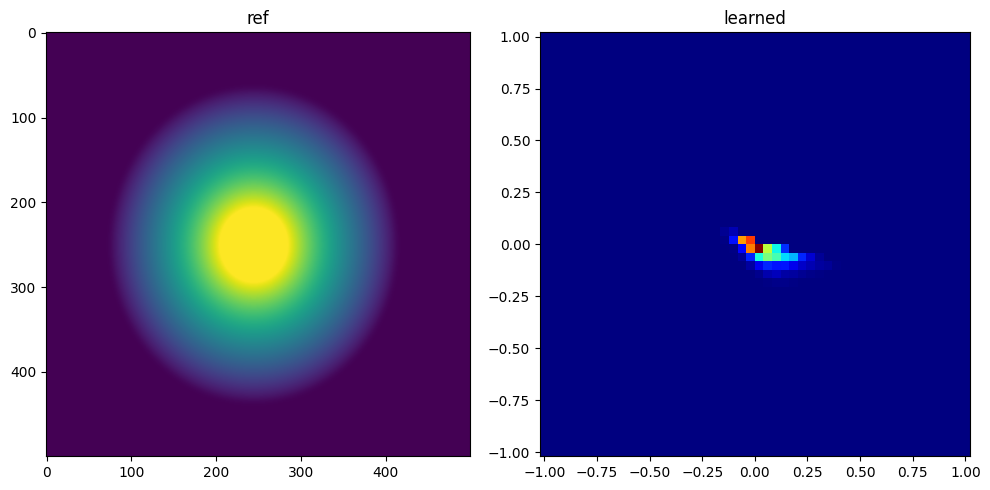

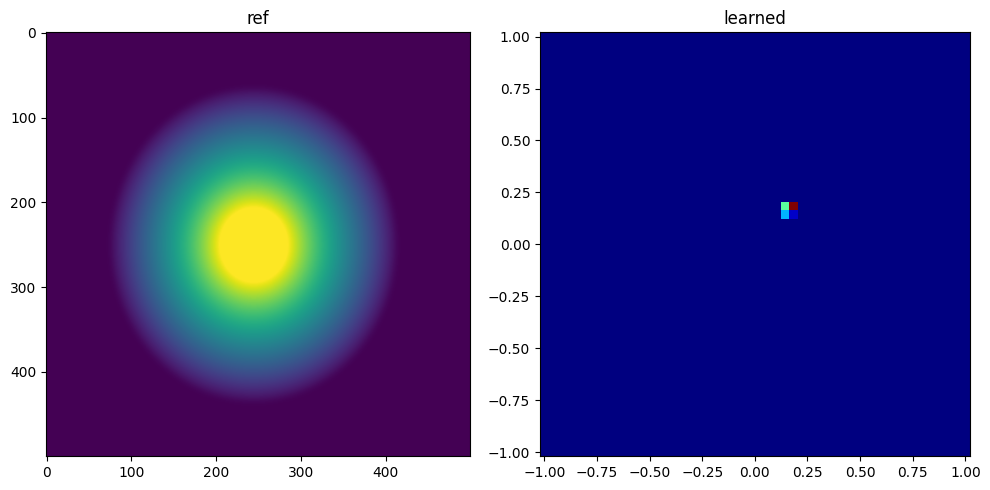

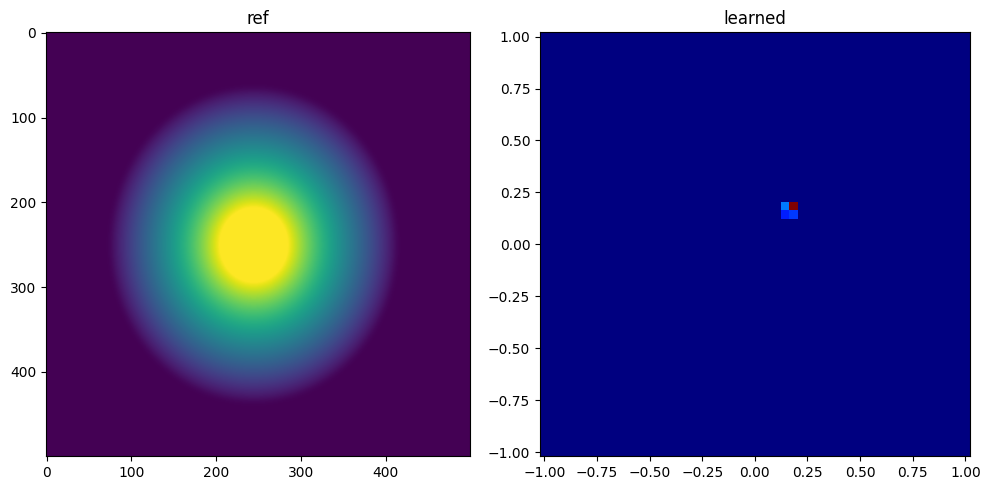

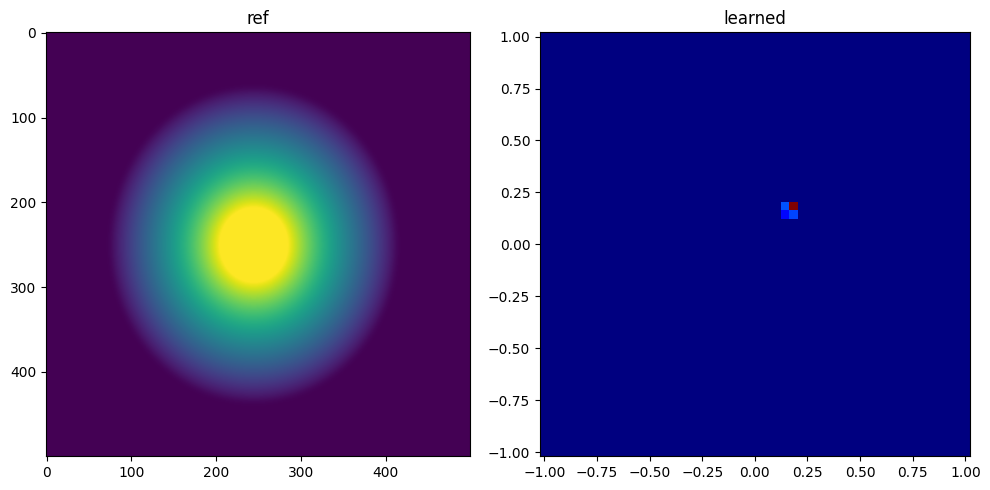

In [ ]:
weights, net = create_net(seed=1)

opt = Adam(lr=1e-2, params={'weights': Float32(weights)})
scaler = GradScaler()

its = 1000
batch_size = 128

alpha = 1e-3

num_training_plots = 3

plot_every = int(its / num_training_plots if num_training_plots > 0 else its + 1)

loss_hist = np.array([])
weight_updates = np.array([])

for i in tqdm(range(its)):
    # Update network state from optimizer
    weight_diff = Float16(opt['weights']) - weights

    mean_weight_update = dr.sum(weight_diff) 

    weight_updates = np.append(weight_updates, mean_weight_update.numpy())


    weights[:] = Float16(opt['weights'])


    # z = rng.random(Array2f, (2, batch_size))
    z = sample_prior_as_Array2f(q0, batch_size)
    
    # log_probs = dr.log(tex.eval(z))

    dr.enable_grad(z)
    
    y = Array2f(net(nn.CoopVec(z)))

    Js = Jac2d(z, y)
    dets = dr.clip(dr.det(Js), min=1e-4, max=1e10)

    y = Array2f(net(nn.CoopVec(z)))

    probs_f = Array1f(target.eval(y))

    Is = I(z)
    probs_I = Array1f(target.eval(Is))
    dets_I = I_abs_det(z)


    f_loss = (1 - alpha) * probs_f * dets
    I_loss =      alpha  * probs_I * dets_I

    losses = -dr.log(f_loss + I_loss)
    loss = dr.mean(losses[0])

    # Mixed-precision training: take suitably scaled steps
    dr.backward(scaler.scale(loss))
    scaler.step(opt)
    
    loss_hist = np.append(loss_hist, loss.numpy())

    if (i != 0 or plot_every < its) and i % plot_every == 0:        
        plot_model(q0, net, ref, num_samples=100000)
        # vis2dModel_loss(net, target, q0)



# plt.figure(figsize=(10, 10))
# # plt.semilogy(loss_hist, label='loss')
# # plt.plot(loss_hist, label='loss')
# plt.plot(weight_updates, label="weight updates")
# plt.legend()
# plt.show()

# Again: Single Dimension test

tensor(1.)


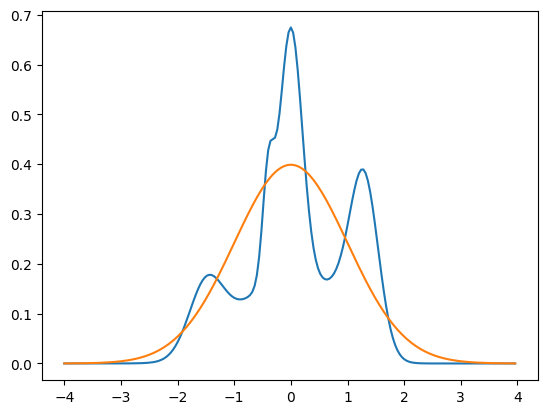

In [26]:
device = 'cpu'

import torch

means = torch.tensor([-1.5, -0.7, -0.4, 0, 0.1, 0.9, 1.3], device = device)
sigmas = torch.tensor([0.3, 0.6, 0.1, 0.2, 0.5, 0.4, 0.25], device = device)
weights = torch.tensor([2, 3, 1, 5, 3, 2, 4], device=device)


sigmas_squared = sigmas.square()
weights = torch.divide(weights, weights.sum())



def eval_gaussian(x, means, sigmas_squared, weights):
    # x = torch.round(x, decimals=0)
    diff_squared = (x.unsqueeze(-1) - means).squeeze(0).square()
    exponent = -0.5 * diff_squared / sigmas_squared
    norm_factor = 1 / torch.sqrt(2 * torch.pi * sigmas_squared)

    individal_pdf = weights * norm_factor * torch.exp(exponent)
    return individal_pdf.sum(dim = 1)

def target(x, k = 10.0):
    return eval_gaussian(x, means, sigmas_squared, weights)
    # floor = eval_gaussian(torch.floor(x), means, sigmas_squared, weights)
    # ceil  = eval_gaussian(torch.ceil(x), means, sigmas_squared, weights)
# 
    # t = torch.frac(x)
# 
    # t = torch.where(t < 0, 1 + t, t)
# 
    # return (1 - t) * floor + t * ceil

    # return (-0.5 * x + 1) * torch.sigmoid(k * x) * torch.sigmoid(k * (2 - x))
    
    # mask = (x >= 0) & (x <= 2)
    # return torch.where(mask, -0.5 * x + 1, torch.full_like(fill_value=1e-4, input=x))

    # return torch.where((x < 0), torch.exp(x) / 3, 2 * torch.exp(-x) / 3)


prior_mean = torch.tensor([0], device = device)
prior_sigma = torch.tensor([1], device = device)
def prior(x):
    return (1 / torch.sqrt(2 * torch.pi * prior_sigma * prior_sigma) * torch.exp(- (x - prior_mean) ** 2 / (2 * (prior_sigma ** 2))))


start = -4
end = 4
num_sample_points = 200
step = (end - start) / num_sample_points

x = torch.arange(start, end, step=step, device = device)
prior_y = prior(x)
y = target(x)

print(y.sum() * step)

plt.plot(x.cpu(), y.cpu())
plt.plot(x.cpu(), prior_y.cpu())

In [27]:
def plot1dmodel(model, 
                device,
                num_test_samples = 1000, 
                start = -2, 
                end = 2, 
                plot_target = True, 
                plot_prior = True, 
                plot_prior_rec = True,
                plot_transform = False, 
                plot_model_reparam = False,
                include_samples = False,
                num_samples = 10000):

    step = (end - start) / num_test_samples

    x_lin = torch.arange(start, end, step, device = device)
    y = target(x_lin)
    p = prior(x_lin)

    jac = torch.func.vmap(torch.func.jacrev(model, chunk_size=1))


    jac_matrices = jac(x_lin.unsqueeze(-1))
    abs_dets = torch.det(jac_matrices)

    model_pdf = abs_dets * p

    transform = model(x_lin.unsqueeze(-1))
    reconstruced_prior = abs_dets * target(transform.squeeze(-1))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

    x_lin = x_lin.cpu()
    if plot_target: 
        ax1.plot(x_lin, y.cpu(), label = "target")
    
    if plot_prior: 
        ax1.plot(x_lin, p.cpu(), label = "prior")
    
    if plot_model_reparam:
        ax1.plot(x_lin, model_pdf.cpu().detach(), label = "model reparam")
    
    if plot_prior_rec:
        ax1.plot(x_lin, reconstruced_prior.cpu().detach(), label = "reconstructed prior")
    
    if plot_transform:
        ax1.plot(x_lin, transform.cpu().detach(), label = "transformed x axis")
        
    if include_samples:
        x = torch.randn(num_samples, device = device)
        pred_samples = model(x.unsqueeze(-1)).cpu().detach().numpy()
        plt.hist(pred_samples, bins=100)

    fig.legend()
    return fig


In [28]:
def Jac1d(x, y):
    dr.forward(x)

    return dr.grad(y)

In [39]:
# Establish the network structure

# HGE = nn.HashGridEncoding(dtype=dr.auto.ad.Float32, dimension=2)
net1d = nn.Sequential(
    # nn.HashEncodingLayer(HGE),
    nn.Cast(Float16),
    nn.Linear(-1, 16, bias=True),
    nn.LeakyReLU(),
    nn.Linear(-1, -1, bias=True),
    nn.LeakyReLU(),
    nn.Linear(-1, -1, bias=True),
    nn.LeakyReLU(),
    nn.Linear(-1, 1, bias=True)
)

# Instantiate a random number generator to initialize the network weights
rng = dr.rng(seed=0)

# Instantiate the network for a specific backend + input size
net1d = net1d.alloc(
    dtype=TensorXf16,
    size=2,
    rng=rng
)

# Convert to training-optimal layout
weights1d, net1d = nn.pack(net1d, layout='training')

opt1d = Adam(lr=1e-3, params={'weights': Float32(weights1d)})
scaler1d = GradScaler()

res = 256

its = 1000
batch_size = 128

alpha = 1e-3

num_training_plots = 2

plot_every = int(its / num_training_plots if num_training_plots > 0 else its + 1)
print(plot_every)

loss_hist = np.array([])
weight_updates = np.array([])

for i in tqdm(range(its)):
    # Update network state from optimizer
    weights1d[:] = Float16(opt1d['weights'])


    z = rng.random(Array1f, (1, batch_size))

    
    # log_probs = dr.log(tex.eval(z))

    dr.enable_grad(z)
    
    coopz = nn.CoopVec(z)
    y = Array1f(net1d(coopz))

    dets = dr.abs(Jac1d(z, y))

    
    y = Array1f(net1d(nn.CoopVec(z)))
    dets = dr.abs(dets)

    f_eval = Array1f(target(torch.from_numpy(y.numpy())).numpy())

    Is = z / dr.sqrt(dr.square(z) + 1)
    probs_I = Array1f(target(torch.from_numpy(Is.numpy())).numpy())
    
    dets_I = 1 / dr.square(dr.square(z) + 1)

    f_loss = (1 - alpha) * f_eval * dets
    I_loss =      alpha  * probs_I * dets_I


    losses = -dr.log(f_loss + I_loss)
    loss = dr.mean(losses[0])

    # Mixed-precision training: take suitably scaled steps
    # dr.backward(scaler.scale(losses[0]))
    # scaler.step(opt)
    loss_hist = np.append(loss_hist, loss.numpy())

    dr.backward(scaler.scale(loss))
    opt.step()

    if i % plot_every == 0:
        print(f"loss: {loss}")
        print(f"scaled loss: {scaler.scale(logMultiprocessing)}")
        # print(weights)
        # print(Float16(opt['weights']))
        # print(f"f: {f_eval}, dets: {dets}")
        
        # plot_model1d(q0, net, ref, num_samples=100000)



plt.figure(figsize=(10, 10))
# plt.semilogy(loss_hist, label='loss')
plt.plot(loss_hist, label='loss')
plt.plot(weight_updates, label="weight updates")
plt.legend()
plt.show()

500


  0%|          | 0/1000 [00:00<?, ?it/s]

RuntimeError: jit_coop_vec_matvec(): incompatible shapes. Attempted to multiply a 16x2 matrix by a vector with 1 elements.